# Stage 4: Data-size scaling experiment (Sparse Autoencoder on Pythia-70M)

**Question:** How much activation data does the SAE need before its held-out reconstruction error, number of live features, and feature interpretability stop improving?



## 0. Environment (same pinned versions as the reproduction)

In [ ]:
!pip install -q transformers==4.36.2 datasets==2.16.1 accelerate==0.25.0

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.8/126.8 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.2/8.2 MB 49.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 507.1/507.1 kB 22.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 265.7/265.7 kB 11.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.3/115.3 kB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 166.4/166.4 kB 8.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 17.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 64.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 135.4/135.4 kB 7.0 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2023.10.0 which is incompatible.
diffusers 

In [ ]:
import json, random, time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from transformers import AutoTokenizer, AutoModelForCausalLM
from datasets import load_dataset

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)   # should say cuda

/usr/local/lib/python3.13/dist-packages/transformers/utils/generic.py:441: FutureWarning: `torch.utils._pytree._register_pytree_node` is deprecated. Please use `torch.utils._pytree.register_pytree_node` instead.
  _torch_pytree._register_pytree_node(


Using device: cuda


## 1. Settings
Same values as the reproduction notebook, except where marked.

In [ ]:
MODEL_NAME = "EleutherAI/pythia-70m"
LAYER = 3
MAX_LENGTH = 128
R = 4                 # dictionary ratio -> 2048 features
ALPHA = 1.0           # the alpha the reproduction settled on
LR = 1e-3
BATCH_SIZE = 64
EPS = 1e-3            # a feature counts as "active" if its activation > EPS (same as reproduction's updated notebook)
SEED = 0

N_TRAIN_DOCS = 5000   # matches the reproduction's full-scale run (~401,882 activations)
N_HELDOUT_DOCS = 500  # NEW: separate documents the SAE never trains on, used for every evaluation

STEPS = 60000         # gradient steps per run, SAME for every data size (see note in section 6)
EVAL_EVERY = 10000    # log held-out metrics this often during training

torch.manual_seed(SEED)
random.seed(SEED)

## 2. Load the frozen model and the text

In [ ]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

model = AutoModelForCausalLM.from_pretrained(MODEL_NAME).to(device)
model.eval()
for p in model.parameters():
    p.requires_grad = False

dataset = load_dataset("wikitext", "wikitext-103-raw-v1", split="train", streaming=True)
texts = []
for example in dataset:
    if len(example["text"].strip()) > 20:
        texts.append(example["text"])
    if len(texts) >= N_TRAIN_DOCS + N_HELDOUT_DOCS:
        break
print("Collected", len(texts), "text samples")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/396 [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/99.0 [00:00<?, ?B/s]

Special tokens have been added in the vocabulary, make sure the associated word embeddings are fine-tuned or trained.


config.json:   0%|          | 0.00/567 [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/transformers/utils/generic.py:309: FutureWarning: `torch.utils._pytree._register_pytree_node` is deprecated. Please use `torch.utils._pytree.register_pytree_node` instead.
  _torch_pytree._register_pytree_node(
/usr/local/lib/python3.13/dist-packages/transformers/utils/generic.py:309: FutureWarning: `torch.utils._pytree._register_pytree_node` is deprecated. Please use `torch.utils._pytree.register_pytree_node` instead.
  _torch_pytree._register_pytree_node(
/usr/local/lib/python3.13/dist-packages/huggingface_hub/file_download.py:949: FutureWarning: `resume_download` is deprecated and will be removed in version 1.0.0. Downloads always resume when possible. If you want to force a new download, use `force_download=True`.
  warnings.warn(


model.safetensors:   0%|          | 0.00/166M [00:00<?, ?B/s]

Collected 5500 text samples


## 3. Collect activations (with document ids)
Same collection as the reproduction, with one addition: we keep track of which document each activation came from, so the held-out set can be a separate set of **documents** (not just separate tokens from the same text, which would leak).

First `N_TRAIN_DOCS` documents = training pool. The next `N_HELDOUT_DOCS` = held-out set.

In [ ]:
@torch.no_grad()
def collect_activations(texts, layer, batch_size=8):
    all_acts, all_ids, all_docs = [], [], []
    for i in range(0, len(texts), batch_size):
        batch = texts[i:i + batch_size]
        inputs = tokenizer(batch, return_tensors="pt", padding=True,
                           truncation=True, max_length=MAX_LENGTH).to(device)
        hidden = model(**inputs, output_hidden_states=True).hidden_states[layer]   # (batch, seq, d_model)
        mask = inputs["attention_mask"].bool()
        all_acts.append(hidden[mask].cpu())
        all_ids.append(inputs["input_ids"][mask].cpu())
        doc_idx = torch.arange(i, i + len(batch), device=device).unsqueeze(1).expand_as(mask)
        all_docs.append(doc_idx[mask].cpu())
    return torch.cat(all_acts), torch.cat(all_ids), torch.cat(all_docs)

pool_acts, pool_ids, pool_docs = collect_activations(texts, LAYER)

is_train = pool_docs < N_TRAIN_DOCS
train_acts = pool_acts[is_train]
heldout_acts = pool_acts[~is_train]
d_model = pool_acts.shape[1]
dict_size = d_model * R

print("all activations :", pool_acts.shape)
print("train pool      :", train_acts.shape[0], "(the reproduction's full run reported 401,882)")
print("held-out        :", heldout_acts.shape[0])

# Variance of the held-out activations around the training mean: a yardstick for "how big is the error"
train_mean = train_acts.mean(dim=0, keepdim=True)
heldout_var = ((heldout_acts - train_mean) ** 2).sum(dim=-1).mean().item()
print("held-out total variance per token:", round(heldout_var, 2))

all activations : torch.Size([439444, 512])
train pool      : 401882 (the reproduction's full run reported 401,882)
held-out        : 37562
held-out total variance per token: 499.3


## 4. The SAE and metrics

`SparseAutoencoder` and `sae_loss` are **exactly the group's code** (reused as-is from the group’s reproduction).
The evaluation function and the training loop are new.

**Metrics (all measured on held-out documents):**
- **MSE per token**: how badly the reconstruction misses (lower = better). This is a per-token average, so it IS comparable across data sizes (unlike the summed-per-epoch numbers in the reproduction).
- **Fraction of variance unexplained**: MSE divided by the held-out variance (0 = perfect, 1 = no better than the mean).
- **L0**: average number of features active per token.
- **Dead features**: features that never fire on any held-out token.

In [ ]:
class SparseAutoencoder(nn.Module):          # reused as-is from the group's reproduction notebook
    def __init__(self, d_model, dict_size):
        super().__init__()
        self.W = nn.Parameter(torch.randn(dict_size, d_model) * 0.1)
        self.b_enc = nn.Parameter(torch.zeros(dict_size))
        with torch.no_grad():
            self.W.data = F.normalize(self.W.data, dim=1)

    def encode(self, x):
        return F.relu(x @ self.W.T + self.b_enc)

    def decode(self, c):
        return c @ self.W

    def forward(self, x):
        c = self.encode(x)
        x_hat = self.decode(c)
        return x_hat, c


def sae_loss(x, x_hat, c, alpha):            # reused as-is from the group's reproduction notebook
    recon_loss = ((x - x_hat) ** 2).sum(dim=-1).mean()
    sparsity_loss = c.abs().sum(dim=-1).mean()
    return recon_loss + alpha * sparsity_loss, recon_loss, sparsity_loss


@torch.no_grad()
def evaluate(sae, data, chunk=8192):
    sae.eval()
    tot_mse, tot_l0, n = 0.0, 0.0, 0
    fired = torch.zeros(dict_size, dtype=torch.bool, device=device)
    for i in range(0, len(data), chunk):
        x = data[i:i + chunk].to(device)
        x_hat, c = sae(x)
        active = c > EPS
        tot_mse += ((x - x_hat) ** 2).sum(dim=-1).sum().item()
        tot_l0 += active.float().sum(dim=-1).sum().item()
        fired |= active.any(dim=0)
        n += len(x)
    sae.train()
    mse = tot_mse / n
    return {"mse": mse, "frac_unexplained": mse / heldout_var, "l0": tot_l0 / n,
            "dead": int((~fired).sum().item()), "fired": fired.cpu()}

In [ ]:
def train_fixed_steps(train_data, alpha=ALPHA, steps=STEPS, batch_size=BATCH_SIZE, lr=LR,
                      eval_every=EVAL_EVERY, seed=SEED):
    """Train an SAE for a FIXED number of gradient steps, sampling random batches from train_data.
    Same initialisation (seed) for every run, so only the amount of data differs."""
    torch.manual_seed(seed)
    sae = SparseAutoencoder(d_model, dict_size).to(device)
    opt = torch.optim.Adam(sae.parameters(), lr=lr)
    data = train_data.to(device)
    n = data.shape[0]
    gen = torch.Generator(device=device)
    gen.manual_seed(seed)
    curve = []
    for step in range(1, steps + 1):
        idx = torch.randint(0, n, (batch_size,), device=device, generator=gen)
        x = data[idx]
        x_hat, c = sae(x)
        loss, recon, sparsity = sae_loss(x, x_hat, c, alpha)
        opt.zero_grad()
        loss.backward()
        opt.step()
        with torch.no_grad():
            sae.W.data = F.normalize(sae.W.data, dim=1)
        if step % eval_every == 0 or step == steps:
            m = evaluate(sae, heldout_acts)
            curve.append({"step": step, "heldout_mse": m["mse"], "l0": m["l0"], "dead": m["dead"]})
    return sae, curve

## 5. Quick test (do this first, takes seconds)
Checks that training and evaluation run and the numbers are finite, using only 500 tokens and 2,000 steps. Don't read anything into these numbers.

In [ ]:
g = torch.Generator()
g.manual_seed(SEED)
perm = torch.randperm(len(train_acts), generator=g)       # one fixed random order of the training tokens

t0 = time.time()
sae_test, curve_test = train_fixed_steps(train_acts[perm[:500]], steps=2000, eval_every=1000)
print("time:", round(time.time() - t0, 1), "s")
print(curve_test)
m = evaluate(sae_test, heldout_acts)
print({k: v for k, v in m.items() if k != "fired"})
assert np.isfinite(m["mse"]), "MSE is not finite, stop and debug before the real run"

time: 4.0 s
[{'step': 1000, 'heldout_mse': 54.218464638464404, 'l0': 58.3374154730845, 'dead': 0}, {'step': 2000, 'heldout_mse': 55.55486595495447, 'l0': 46.084021085139234, 'dead': 0}]
{'mse': 55.55486595495447, 'frac_unexplained': 0.11126525471253172, 'l0': 46.084021085139234, 'dead': 0}


## 6. The experiment
Train one SAE per data size and evaluate each on the **same held-out documents**.

**How the subsets are made:** one fixed random ordering of all training tokens; a size of N means "the first N tokens of that ordering". So every smaller set is contained in every larger one, and all sizes come from the same mix of documents (this isolates *amount* of data, not topic mix).

**Why a fixed number of steps:** every run gets the same compute budget (60,000 steps of batch size 64, about 3.8 million training samples). With little data the SAE sees the same tokens thousands of times and can memorise them; with the full set it sees each token about 10 times. The convergence plot in section 7 shows that held-out MSE for the largest sizes is flat well before 60,000 steps, so the budget was sufficient.

In [ ]:
SIZES = [500, 2000, 8000, 32000, 128000, len(train_acts)]

saes, results, curves, fired_by_size = {}, [], {}, {}
for size in SIZES:
    print(f"=== training on {size} tokens ===")
    t0 = time.time()
    subset = train_acts[perm[:size]]
    sae_i, curve = train_fixed_steps(subset)
    m = evaluate(sae_i, heldout_acts)
    tr = evaluate(sae_i, subset[:20000])              # error on (up to 20k) tokens it trained on
    row = {"size": size, "heldout_mse": m["mse"], "heldout_frac_unexplained": m["frac_unexplained"],
           "l0": m["l0"], "dead": m["dead"], "dead_pct": 100 * m["dead"] / dict_size,
           "train_mse": tr["mse"], "seconds": round(time.time() - t0)}
    print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in row.items()})
    saes[size], curves[size], fired_by_size[size] = sae_i, curve, m["fired"]
    results.append(row)
    torch.save(sae_i.state_dict(), f"sae_datasize_{size}.pt")

results_df = pd.DataFrame(results)
results_df.to_csv("datasize_results.csv", index=False)
results_df

=== training on 500 tokens ===
{'size': 500, 'heldout_mse': 61.209, 'heldout_frac_unexplained': 0.123, 'l0': 30.765, 'dead': 0, 'dead_pct': 0.0, 'train_mse': 5.462, 'seconds': 104}
=== training on 2000 tokens ===
{'size': 2000, 'heldout_mse': 52.815, 'heldout_frac_unexplained': 0.106, 'l0': 19.048, 'dead': 0, 'dead_pct': 0.0, 'train_mse': 9.88, 'seconds': 103}
=== training on 8000 tokens ===
{'size': 8000, 'heldout_mse': 39.711, 'heldout_frac_unexplained': 0.08, 'l0': 25.793, 'dead': 3, 'dead_pct': 0.146, 'train_mse': 20.059, 'seconds': 103}
=== training on 32000 tokens ===
{'size': 32000, 'heldout_mse': 31.62, 'heldout_frac_unexplained': 0.063, 'l0': 31.067, 'dead': 3, 'dead_pct': 0.146, 'train_mse': 25.177, 'seconds': 103}
=== training on 128000 tokens ===
{'size': 128000, 'heldout_mse': 29.18, 'heldout_frac_unexplained': 0.058, 'l0': 32.025, 'dead': 6, 'dead_pct': 0.293, 'train_mse': 26.911, 'seconds': 104}
=== training on 401882 tokens ===
{'size': 401882, 'heldout_mse': 28.399, 'h

,size,heldout_mse,heldout_frac_unexplained,l0,dead,dead_pct,train_mse,seconds
0,500,61.208554,0.122588,30.764762,0,0.000000,5.461994,104
1,2000,52.815413,0.105779,19.047655,0,0.000000,9.880363,103
2,8000,39.711137,0.079533,25.792796,3,0.146484,20.058549,103
3,32000,31.619985,0.063328,31.067089,3,0.146484,25.176557,103
4,128000,29.179867,0.058441,32.025371,6,0.292969,26.910853,104
5,401882,28.398851,0.056877,32.614611,16,0.781250,26.978424,104


## 7. Results: table, plots, convergence check
Held-out error, dead features and L0 against data size, train vs held-out error, and a convergence check of held-out MSE during training.

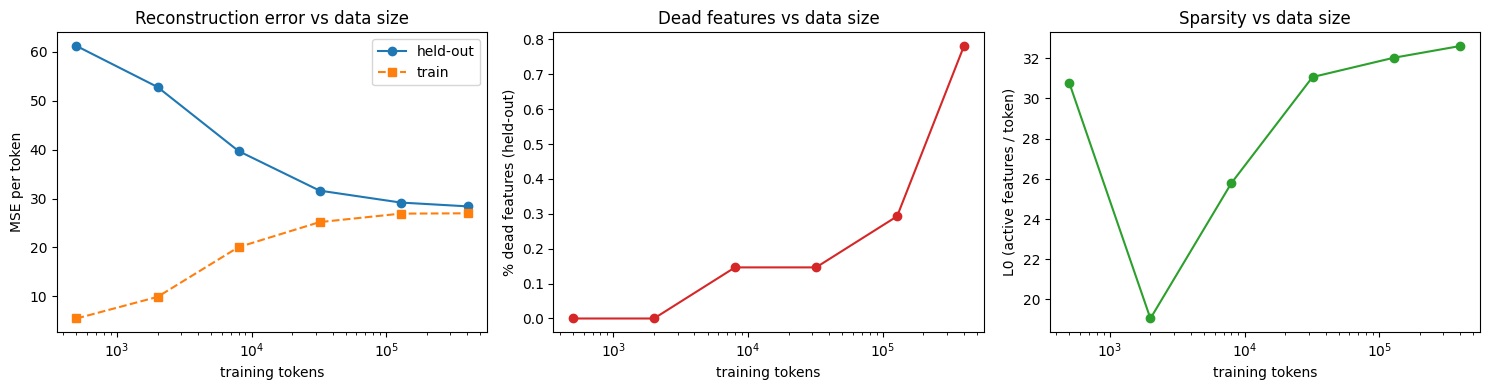

  size  heldout_mse  heldout_frac_unexplained     l0  dead  dead_pct  train_mse
   500       61.209                     0.123 30.765     0     0.000      5.462
  2000       52.815                     0.106 19.048     0     0.000      9.880
  8000       39.711                     0.080 25.793     3     0.146     20.059
 32000       31.620                     0.063 31.067     3     0.146     25.177
128000       29.180                     0.058 32.025     6     0.293     26.911
401882       28.399                     0.057 32.615    16     0.781     26.978


In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

ax[0].plot(results_df["size"], results_df["heldout_mse"], "o-", label="held-out")
ax[0].plot(results_df["size"], results_df["train_mse"], "s--", label="train")
ax[0].set_xscale("log"); ax[0].set_xlabel("training tokens"); ax[0].set_ylabel("MSE per token")
ax[0].set_title("Reconstruction error vs data size"); ax[0].legend()

ax[1].plot(results_df["size"], results_df["dead_pct"], "o-", color="tab:red")
ax[1].set_xscale("log"); ax[1].set_xlabel("training tokens"); ax[1].set_ylabel("% dead features (held-out)")
ax[1].set_title("Dead features vs data size")

ax[2].plot(results_df["size"], results_df["l0"], "o-", color="tab:green")
ax[2].set_xscale("log"); ax[2].set_xlabel("training tokens"); ax[2].set_ylabel("L0 (active features / token)")
ax[2].set_title("Sparsity vs data size")

plt.tight_layout()
plt.savefig("datasize_main_plots.png", dpi=200)
plt.show()

print(results_df[["size", "heldout_mse", "heldout_frac_unexplained", "l0", "dead", "dead_pct", "train_mse"]].round(3).to_string(index=False))

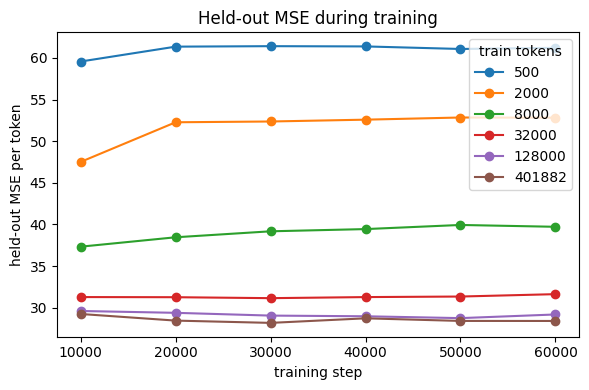

In [ ]:
# Convergence check: held-out MSE during training for every size.
# If the curve for the LARGEST size is still clearly going down at the end, raise STEPS and rerun.
plt.figure(figsize=(6, 4))
for size in SIZES:
    c = curves[size]
    plt.plot([r["step"] for r in c], [r["heldout_mse"] for r in c], "o-", label=str(size))
plt.xlabel("training step"); plt.ylabel("held-out MSE per token"); plt.legend(title="train tokens")
plt.title("Held-out MSE during training")
plt.tight_layout()
plt.savefig("datasize_convergence.png", dpi=200)
plt.show()

## 8. Qualitative check: are features cleaner with more data?
MSE and L0 do not tell you whether features mean anything. So we score features by eye, as the reproduction did, but more carefully:

- For 3 data sizes we randomly pick 10 features that actually fire, and show the 5 contexts where each fires most strongly (the activating token is in `[[double brackets]]`).
- The items are shuffled and anonymised, so the scorer does not know which data size an item comes from. Scored blind by one team member.
- **Scoring rubric:** `2` = the examples clearly share one idea (a topic, word type or pattern), `1` = partly, `0` = unclear or mixed.

In [ ]:
pool_all = pool_acts                # all documents, train + held-out, in the same order as pool_ids / pool_docs

@torch.no_grad()
def feature_activations(sae, feat_ids, chunk=8192):
    W = sae.W[feat_ids]             # (k, d_model)
    b = sae.b_enc[feat_ids]
    out = []
    for i in range(0, len(pool_all), chunk):
        x = pool_all[i:i + chunk].to(device)
        out.append(F.relu(x @ W.T + b).cpu())
    return torch.cat(out)           # (num_tokens, k)

def context(i, w=8):
    d = pool_docs[i].item()
    s = i
    while s > max(0, i - w) and pool_docs[s - 1].item() == d:
        s -= 1
    e = i + 1
    while e < min(len(pool_ids), i + 1 + w) and pool_docs[e].item() == d:
        e += 1
    before = tokenizer.decode(pool_ids[s:i])
    tok = tokenizer.decode(pool_ids[i:i + 1])
    after = tokenizer.decode(pool_ids[i + 1:e])
    return (before + " [[" + tok + "]] " + after).replace("\n", " ")

def top_contexts(acts_col, k=5):
    top_idx = acts_col.topk(30).indices.tolist()
    seen_docs, out = set(), []
    for i in top_idx:
        d = pool_docs[i].item()
        if d in seen_docs:
            continue
        seen_docs.add(d)
        out.append(f"{acts_col[i].item():.2f} | {context(i)}")
        if len(out) == k:
            break
    return out

SCORE_SIZES = [SIZES[0], SIZES[2], SIZES[-1]]
N_SCORE = 10
rng = random.Random(0)

rows = []
for size in SCORE_SIZES:
    alive = fired_by_size[size].nonzero().flatten().tolist()
    chosen = rng.sample(alive, min(N_SCORE, len(alive)))
    acts_sel = feature_activations(saes[size], chosen)
    for j, fid in enumerate(chosen):
        rows.append({"size": size, "feature": fid, "examples": "\n".join(top_contexts(acts_sel[:, j]))})

rng.shuffle(rows)
for item_id, r in enumerate(rows):
    r["item_id"] = item_id

pd.DataFrame([{"item_id": r["item_id"], "examples": r["examples"], "score": ""} for r in rows]).to_csv("scoring_sheet.csv", index=False)
pd.DataFrame([{"item_id": r["item_id"], "size": r["size"], "feature": r["feature"]} for r in rows]).to_csv("scoring_key.csv", index=False)
print(len(rows), "items written. Share scoring_sheet.csv with the scorers. Keep scoring_key.csv to yourself until they are done.")
print()
for r in rows[:2]:
    print("item", r["item_id"]); print(r["examples"]); print()

30 items written. Share scoring_sheet.csv with the scorers. Keep scoring_key.csv to yourself until they are done.

item 0
3.30 |  " cleaning of the mouth ", to [[ link]]  his name with his role in the Opening
3.24 |  father by the child, a pattern that [[ connects]]  divine families with royal succession. Osir
3.23 |  to the gods, as he formed a [[ link]]  between the divine and human realms.
3.05 | 's portrayal as their teacher is [[ connected]]  to a recurring element in Chinese fiction where
2.98 |  Amtrak's Texas Eagle via [[ connecting]]  bus service at Longview, Texas.

item 1
5.72 |  New York, where he attended James Madison [[ High]]  School. In his memoir, Fink
4.21 |  in the school bands at Janesville [[ High]]  School and Monroe High
3.85 |  Ohio. He graduated from Sandusky [[ High]]  School.  
3.82 |  companies to the aid of the Seaforth [[ High]] landers, as Seaforth B Company attacked
3.50 | onide affinity, similar to the Scottish [[ High]] lands. Across southeast Ulster 

### Collecting the scores
Scores were entered in the `score` column of `scoring_sheet.csv` and saved as `scoring_sheet_scored.csv`. The cell below joins them with `scoring_key.csv` (opened only after scoring was finished) and averages by data size.

        mean_score  pct_clear   n
size                             
500            1.7       80.0  10
8000           1.8       80.0  10
401882         1.8       80.0  10


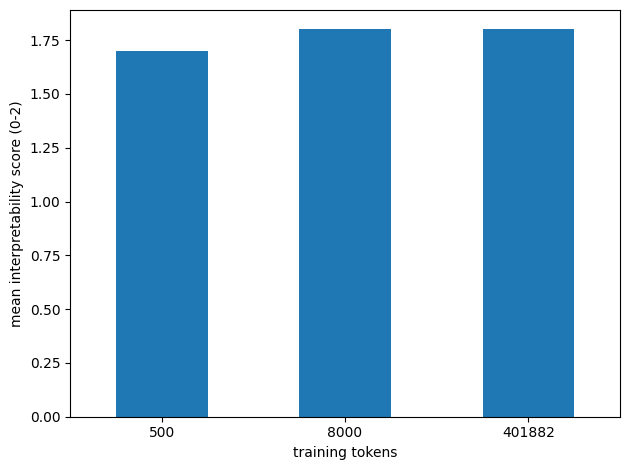

In [ ]:
# Put the names of the filled-in CSV files here (one per scorer)
SCORED_FILES = ["scoring_sheet_scored.csv"]

key = pd.read_csv("scoring_key.csv")
all_scores = []
for fname in SCORED_FILES:
    s = pd.read_csv(fname)[["item_id", "score"]].rename(columns={"score": f"score_{fname}"})
    key = key.merge(s, on="item_id")
score_cols = [c for c in key.columns if c.startswith("score_")]
key["mean_score"] = key[score_cols].mean(axis=1)

summary = key.groupby("size").agg(mean_score=("mean_score", "mean"),
                                  pct_clear=("mean_score", lambda v: 100 * (v >= 1.5).mean()),
                                  n=("mean_score", "size"))
print(summary.round(2))
summary["mean_score"].plot(kind="bar", ylabel="mean interpretability score (0-2)", xlabel="training tokens", rot=0)
plt.tight_layout(); plt.savefig("datasize_interpretability.png", dpi=200); plt.show()

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

MessageError: Error: credential propagation was unsuccessful

## 9. Provenance
- `SparseAutoencoder`, `sae_loss`: reused as-is from the group's reproduction notebook (sae_reproduction_starterupdate.ipynb).
- `collect_activations`: adapted from the group's notebook (adds document ids so held-out documents can be separated; activation collection is otherwise unchanged).
- `train_fixed_steps`, `evaluate`, subset construction, plotting, scoring-sheet and aggregation code: written for this experiment.
- AI assistance: we took help from an AI assistant (Claude) for this experiment's code. We ran the experiment, scored the features and checked the results ourselves.